# Error Analysis: Rare Clause Categories - Aarabhi Kuchi

This notebook analyses the mistakes of the final model, weighted Legal-BERT, on the 13 clause categories that make up under 1% of the training chunks. For each category it looks at false positives and false negatives, identifies patterns in the errors, and proposes improvements.

**Terms**
- **False negative (FN):** the chunk contains the clause, but the model did not flag it.
- **False positive (FP):** the model flagged the clause, but the chunk does not contain it.
- **Chunk:** an overlapping 512-token piece of a contract. Scores are per chunk unless stated otherwise.

**Setup**
- Model: `nlpaueb/legal-bert-base-uncased` fine-tuned with a weighted loss, decision threshold 0.5.
- Test set: 2,898 chunks from 102 held-out contracts.
- Inputs: `data/processed/` (labeled chunks, category list), `data/test.json` (annotated clause text), and the test-set probabilities in `results/training/15ep/`. The weighted model's predictions are stored on the team Drive (`results/training/15ep/legal-bert-weighted/`) and are not committed to the repository.

## 1. Setup

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 200)

THRESHOLD = 0.5                # decision threshold used for the final model
KEYS = ["title", "chunk_id"]   # these two columns identify one chunk

# Locate the repository root whether the kernel starts in the root or in notebooks/
working_directory = Path.cwd().resolve()
ROOT = next(
    (folder for folder in [working_directory, *working_directory.parents]
     if (folder / "data/processed/test_chunks_labeled.parquet").is_file()
     and (folder / "notebooks").is_dir()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Run this notebook from inside the project repository.")

PRED_PATH = ROOT / "results/training/15ep/legal-bert-weighted/test_predictions.parquet"
UNWEIGHTED_PATH = ROOT / "results/training/15ep/legal-bert/test_predictions.parquet"
MODEL_NAME = "legal-bert-weighted"

for path in [PRED_PATH, UNWEIGHTED_PATH]:
    if not path.is_file():
        raise FileNotFoundError(f"Required predictions file is missing: {path.relative_to(ROOT)}")
print("Project folder:", ROOT)
print("Model:", MODEL_NAME)

Project folder: C:\Users\aarab\Accenture-1H-contract-review-challenge
Model: legal-bert-weighted


## 2. Load and merge the data

Labels and predictions share the same 41 category columns (0/1 truth and probabilities), so they are merged on `title` and `chunk_id` and the columns get `_true` and `_prob` suffixes. Rows are matched by key rather than by position.

In [2]:
categories = json.load(open(ROOT / "data/processed/categories.json"))
preds = pd.read_parquet(PRED_PATH)
labels = pd.read_parquet(ROOT / "data/processed/test_chunks_labeled.parquet")
train = pd.read_parquet(ROOT / "data/processed/train_chunks_labeled.parquet", columns=categories)

assert not labels.duplicated(KEYS).any(), "duplicate chunks in labels"
assert not preds.duplicated(KEYS).any(), "duplicate chunks in predictions"

merged = labels.merge(preds, on=KEYS, how="inner", suffixes=("_true", "_prob"))
assert len(merged) == len(labels) == len(preds), "some chunks did not match"

# Arrays of shape (n_chunks, 41); column j corresponds to categories[j]
y_true = merged[[f"{c}_true" for c in categories]].to_numpy().astype(int)
y_prob = merged[[f"{c}_prob" for c in categories]].to_numpy()
y_pred = (y_prob >= THRESHOLD).astype(int)

print("categories:", len(categories))
print("test chunks:", len(merged), "| contracts:", merged.title.nunique())

categories: 41
test chunks: 2898 | contracts: 102


## 3. Rare categories

A category is rare if it is positive in under 1% of the training chunks. Price Restrictions (0 positives) and Source Code Escrow (2 positives) have too few test examples to analyse, so they are reported in the counts but left out of the pattern analysis.

In [3]:
train_share = train[categories].mean().sort_values()
rare = train_share[train_share < 0.01].index.tolist()
TINY = ["Price Restrictions", "Source Code Escrow"]   # too few test positives to analyse
analysed = [c for c in rare if c not in TINY]

print(len(rare), "rare categories")
display((train_share[rare] * 100).round(2).rename("% of train chunks").to_frame())

13 rare categories


,% of train chunks
Unlimited/All-You-Can-Eat-License,0.22
Price Restrictions,0.24
Third Party Beneficiary,0.30
Source Code Escrow,0.33
Most Favored Nation,0.36
No-Solicit Of Customers,0.37
Affiliate License-Licensor,0.44
Non-Disparagement,0.45
No-Solicit Of Employees,0.61
Joint Ip Ownership,0.70


## 4. Errors by category

In [4]:
rows = []
for c in rare:
    j = categories.index(c)
    t, p = y_true[:, j], y_pred[:, j]
    tp = int(((t == 1) & (p == 1)).sum())
    fp = int(((t == 0) & (p == 1)).sum())
    fn = int(((t == 1) & (p == 0)).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    rows.append(dict(category=c, test_positives=int(t.sum()), TP=tp, FP=fp, FN=fn,
                     precision=round(precision, 2), recall=round(recall, 2), f1=round(f1, 2)))

counts = pd.DataFrame(rows).set_index("category")
display(counts)
print("Total errors across the 13 rare categories:  FP =", counts.FP.sum(), " FN =", counts.FN.sum())

,test_positives,TP,FP,FN,precision,recall,f1
category,,,,,,,
Unlimited/All-You-Can-Eat-License,5,2,1,3,0.67,0.40,0.50
Price Restrictions,0,0,2,0,0.00,0.00,0.00
Third Party Beneficiary,15,7,8,8,0.47,0.47,0.47
Source Code Escrow,2,2,0,0,1.00,1.00,1.00
Most Favored Nation,5,1,1,4,0.50,0.20,0.29
No-Solicit Of Customers,18,10,13,8,0.43,0.56,0.49
Affiliate License-Licensor,22,10,12,12,0.45,0.45,0.45
Non-Disparagement,15,7,4,8,0.64,0.47,0.54
No-Solicit Of Employees,19,17,5,2,0.77,0.89,0.83


Total errors across the 13 rare categories:  FP = 106  FN = 86


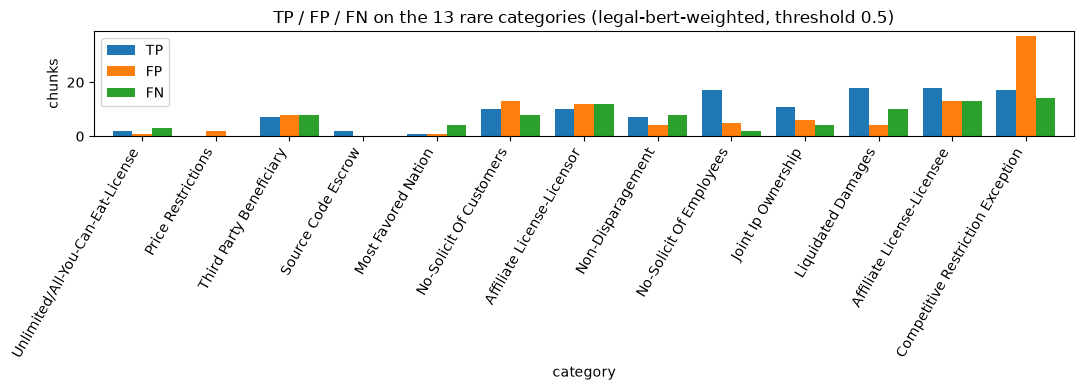

In [5]:
ax = counts[["TP", "FP", "FN"]].plot(kind="bar", figsize=(11, 4), width=0.8)
ax.set_ylabel("chunks")
ax.set_title(f"TP / FP / FN on the 13 rare categories ({MODEL_NAME}, threshold {THRESHOLD})")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

## 5. Effect of class weighting

The weighted loss gives rare positives more influence during training. This compares false negatives and false positives for the unweighted and the weighted Legal-BERT on the same test chunks.

In [6]:
uw = merged[KEYS].merge(pd.read_parquet(UNWEIGHTED_PATH), on=KEYS, how="left")
assert uw[categories].notna().all().all()
uw_pred = (uw[categories].to_numpy() >= THRESHOLD).astype(int)

rows = []
for c in rare:
    j = categories.index(c)
    t = y_true[:, j]
    rows.append(dict(
        category=c,
        FN_unweighted=int(((t == 1) & (uw_pred[:, j] == 0)).sum()),
        FN_weighted=int(((t == 1) & (y_pred[:, j] == 0)).sum()),
        FP_unweighted=int(((t == 0) & (uw_pred[:, j] == 1)).sum()),
        FP_weighted=int(((t == 0) & (y_pred[:, j] == 1)).sum()),
    ))
weighting = pd.DataFrame(rows).set_index("category")
display(weighting)
print("TOTAL", weighting.sum().to_dict())

,FN_unweighted,FN_weighted,FP_unweighted,FP_weighted
category,,,,
Unlimited/All-You-Can-Eat-License,5,3,0,1
Price Restrictions,0,0,0,2
Third Party Beneficiary,15,8,0,8
Source Code Escrow,2,0,0,0
Most Favored Nation,5,4,0,1
No-Solicit Of Customers,13,8,4,13
Affiliate License-Licensor,20,12,1,12
Non-Disparagement,9,8,0,4
No-Solicit Of Employees,5,2,6,5


TOTAL {'FN_unweighted': 143, 'FN_weighted': 86, 'FP_unweighted': 19, 'FP_weighted': 106}


Weighting cut false negatives from 143 to 86 but raised false positives from 19 to 106, so total errors rose from 162 to 192. The new false alarms are concentrated in Competitive Restriction Exception (3 to 37), No-Solicit Of Customers (4 to 13), Affiliate License-Licensee (3 to 13), Affiliate License-Licensor (1 to 12) and Third Party Beneficiary (0 to 8).

## 6. Model confidence on errors

A false negative between 0.2 and 0.5 is a near miss that a lower threshold could recover. A false negative under 0.2 would stay missed at any reasonable threshold. A false positive at 0.8 or above is a confident mistake.

In [7]:
records = []
for c in rare:
    j = categories.index(c)
    for idx in np.where(y_true[:, j] != y_pred[:, j])[0]:
        records.append(dict(
            category=c,
            error="FN" if y_true[idx, j] == 1 else "FP",
            prob=float(y_prob[idx, j]),
            row=int(idx),
            title=merged.at[idx, "title"],
            chunk_id=merged.at[idx, "chunk_id"],
        ))
errors = pd.DataFrame(records)

errors["bucket"] = pd.cut(errors.prob, [0, 0.2, 0.5, 0.8, 1.0001], right=False,
                          labels=["under 0.2", "0.2 to 0.5", "0.5 to 0.8", "0.8 and up"])
display(pd.crosstab(errors.error, errors.bucket))
display(pd.crosstab(errors.category, [errors.error, errors.bucket]))

bucket,under 0.2,0.2 to 0.5,0.5 to 0.8,0.8 and up
error,,,,
FN,65,21,0,0
FP,0,0,75,31


error                                    FN                    FP           
bucket                            under 0.2 0.2 to 0.5 0.5 to 0.8 0.8 and up
category                                                                    
Affiliate License-Licensee               10          3         11          2
Affiliate License-Licensor                9          3         10          2
Competitive Restriction Exception         6          8         29          8
Joint Ip Ownership                        2          2          5          1
Liquidated Damages                        9          1          3          1
Most Favored Nation                       4          0          1          0
No-Solicit Of Customers                   7          1          9          4
No-Solicit Of Employees                   1          1          1          4
Non-Disparagement                         6          2          3          1
Price Restrictions                        0          0          1          1
Third Party Beneficiary                   8          0          1          7
Unlimited/All-You-Can-Eat-License         3          0          1          0

65 of the 86 false negatives score under 0.2 and only 21 fall between 0.2 and 0.5. Most misses are therefore not threshold problems, which is consistent with the Task #3 result that per-category thresholds did not help. On the false-positive side, 31 of 106 are above 0.8.

## 7. Contract-level view

A clause usually appears in several overlapping chunks. This section checks whether the model flagged each clause in at least one chunk of the contract, which is the level the risk-scoring layer works at.

In [8]:
rows = []
for c in rare:
    j = categories.index(c)
    g = (pd.DataFrame({"t": merged.title, "y": y_true[:, j], "p": y_pred[:, j]})
           .groupby("t").agg(y=("y", "max"), p=("p", "max")))
    rows.append(dict(category=c,
                     contracts_with_clause=int(g.y.sum()),
                     flagged=int(((g.y == 1) & (g.p == 1)).sum()),
                     missed=int(((g.y == 1) & (g.p == 0)).sum()),
                     false_alarm_contracts=int(((g.y == 0) & (g.p == 1)).sum())))
contract_level = pd.DataFrame(rows).set_index("category")
display(contract_level)

ok = contract_level.drop(index=TINY)
print("Excluding Price Restrictions and Source Code Escrow: contracts with the clause =",
      ok.contracts_with_clause.sum(), "| flagged =", ok.flagged.sum(), "| missed =", ok.missed.sum())

,contracts_with_clause,flagged,missed,false_alarm_contracts
category,,,,
Unlimited/All-You-Can-Eat-License,3,2,1,1
Price Restrictions,0,0,0,2
Third Party Beneficiary,6,4,2,3
Source Code Escrow,1,1,0,0
Most Favored Nation,3,1,2,1
No-Solicit Of Customers,7,4,3,5
Affiliate License-Licensor,6,3,3,7
Non-Disparagement,7,5,2,4
No-Solicit Of Employees,10,10,0,1


Excluding Price Restrictions and Source Code Escrow: contracts with the clause = 91 | flagged = 68 | missed = 23


Across the 11 analysable categories, 91 contracts contain the clause and the model flagged it in 68 (75%), missing 23. Chunk-level recall is lower because one missed clause often shows up as several missed chunks.

## 8. Reviewing individual errors

For false negatives, the annotated clause text from `data/test.json` is shown, which makes it clear what the model failed to recognise. For false positives, the start of the chunk is shown together with its true labels and the other labels the model predicted.

In [9]:
raw_test = json.load(open(ROOT / "data/test.json"))
gold = {}   # (contract title, category) -> list of (start position, annotated text)
for d in raw_test["data"]:
    for p in d["paragraphs"]:
        for qa in p["qas"]:
            cat = qa["id"].split("__")[-1]
            gold[(d["title"], cat)] = ([] if qa["is_impossible"]
                                       else [(a["answer_start"], a["text"]) for a in qa["answers"]])


def show_missed_clauses(category, n=4, width=260, seed=1):
    """Print the annotated clause text for n random false negatives of a category."""
    j = categories.index(category)
    rows = errors[(errors.category == category) & (errors.error == "FN")].row.values
    print(f"##### {category}: {len(rows)} missed chunks, showing {min(n, len(rows))}\n")
    for i in np.random.RandomState(seed).permutation(rows)[:n]:
        t, cs, ce = merged.at[i, "title"], merged.at[i, "char_start"], merged.at[i, "char_end"]
        spans_here = [txt for start, txt in gold[(t, category)] if cs <= start < ce]
        text = (" ".join(spans_here[0].split())[:width] if spans_here
                else "(no annotation starts in this chunk: the clause began in an earlier chunk)")
        print(f"  prob={y_prob[i, j]:.2f} | chunk {merged.at[i, 'chunk_id']} | {text}")
    print()


def show_false_alarms(category, n=5, width=700, seed=0):
    """Print n random false positives of a category with their true and predicted labels."""
    j = categories.index(category)
    rows = errors[(errors.category == category) & (errors.error == "FP")]
    print(f"##### {category}: {len(rows)} false alarms, showing {min(n, len(rows))}\n")
    for _, r in rows.sample(min(n, len(rows)), random_state=seed).iterrows():
        i = r.row
        other_true = [c for k, c in enumerate(categories) if y_true[i, k] and k != j]
        other_pred = [c for k, c in enumerate(categories) if y_pred[i, k] and k != j]
        print(f"prob={r.prob:.2f} | {r.title[:60]} | chunk {r.chunk_id}")
        print("  true labels (other):     ", other_true or "none")
        print("  predicted labels (other):", other_pred or "none")
        print("  text:", " ".join(merged.at[i, "chunk_text"].split())[:width], "...\n")

### 8.1 Competitive Restriction Exception

In [10]:
show_missed_clauses("Competitive Restriction Exception")
show_false_alarms("Competitive Restriction Exception")

##### Competitive Restriction Exception: 14 missed chunks, showing 4

  prob=0.20 | chunk 2 | Notwithstanding the foregoing, Excite may make available opportunities on the Excite Site to purchase Music Products from parties other than Sponsor if such Music Products are not available from Sponsor so long as, prior to entering into arrangements to make a
  prob=0.44 | chunk 19 | During the Term, MMT shall not Commercialize in any manner any Competing Product in the Field in any country in the Territory; provided, however, the Parties hereby acknowledge that the restrictions set forth in this Section 2.3 shall not apply to any Affiliat
  prob=0.03 | chunk 5 | Notwithstanding the foregoing, this Section 2.2 shall not be deemed to apply to agreements executed prior to the date of this Agreement between the HOF Entities and Johnson Controls, Inc. or any of its affiliates.
  prob=0.32 | chunk 11 | The parties acknowledge that the foregoing will not prevent CNET from displaying text links and 

The annotated clauses are carve-outs: "Notwithstanding the foregoing, ...", "provided, however, ... shall not apply to ...", "will not prevent CNET from displaying ...". The false alarms are mostly the restrictions themselves (non-compete and exclusivity language), so the model picks up the restriction rather than the exception to it.

### 8.2 No-Solicit Of Customers

In [11]:
show_missed_clauses("No-Solicit Of Customers")
show_false_alarms("No-Solicit Of Customers")

##### No-Solicit Of Customers: 8 missed chunks, showing 4

  prob=0.00 | chunk 21 | (no annotation starts in this chunk: the clause began in an earlier chunk)
  prob=0.01 | chunk 2 | KCI pledges that it will not circumvent the relationships among venders, providers and clients developed by Provider either directly or indirectly, during the contract period and for a period of up to 2 (two) years following termination of this contract
  prob=0.16 | chunk 6 | Sekisui shall not, and shall cause its subdistributors not to, market, rent or sell any Products to the Qualigen Retained Customers. 3. Supply;
  prob=0.04 | chunk 41 | In consideration for such training, trade secrets and confidential information, you and your principals agree that during the term of this Agreement, and for a continuous uninterrupted period commencing upon expiration or termination of this Agreement, regardl

##### No-Solicit Of Customers: 13 false alarms, showing 5

prob=0.55 | Monsanto Company - SECOND A_R EXCLUSI

All 13 false alarms are chunks that truly carry Non-Compete. In the sampled misses the customer restriction is worded without "solicit", for example "shall not ... sell any Products to the Qualigen Retained Customers", so the model appears to rely on the keyword.

### 8.3 Affiliate License-Licensor and Affiliate License-Licensee

In [12]:
show_missed_clauses("Affiliate License-Licensor")
show_false_alarms("Affiliate License-Licensor")

##### Affiliate License-Licensor: 12 missed chunks, showing 4

  prob=0.02 | chunk 4 | "AbbVie Know-How" means all Information that is (a) Controlled by AbbVie or any of its Affiliates during the Term, (b) developed or acquired by AbbVie or any of its Affiliates during the Term as a result of performance under this Agreement, (c) not generally k
  prob=0.00 | chunk 5 | "AbbVie Know-How" means all Information that is (a) Controlled by AbbVie or any of its Affiliates during the Term, (b) developed or acquired by AbbVie or any of its Affiliates during the Term as a result of performance under this Agreement, (c) not generally k
  prob=0.00 | chunk 16 | "Harpoon Patents" means all of the Patents that are (a) Controlled by Harpoon or any of its Affiliates as of the Effective Date or at any time during the Term and (b) necessary or reasonably useful (or, with respect to Patent applications, would be necessary o
  prob=0.10 | chunk 35 | You hereby grant to us (and agree to obtain from your af

Most false alarms are ordinary License Grant chunks (10 of 12 for Licensor, 11 of 13 for Licensee), which the model confuses with licenses that extend to affiliates. In the sampled Licensor misses, two of four are definitions such as "'Harpoon Patents' means all of the Patents that are Controlled by Harpoon or any of its Affiliates ...", where the affiliate licensing is embedded in a defined term.

### 8.4 Liquidated Damages

In [13]:
show_missed_clauses("Liquidated Damages")

##### Liquidated Damages: 10 missed chunks, showing 4

  prob=0.01 | chunk 52 | The Transporter shall only accept extemporary nominations as long as the Pipeline has available Capacity. If the nomination is accepted, the Third Party or Sender shall Pay to the Transporter as a penalty, two (2%) of the applicable rate to the volumes in barr
  prob=0.00 | chunk 12 | In addition, TPC agrees that Consolidated Artists shall be entitled to the Retainer Fee prorated to the effective date of termination as well any Tournament Bonuses, Money List Bonuses and any Royalty Compensation earned by Consolidated Artists prior to the ef
  prob=0.00 | chunk 6 | In the event the closing does not occur, the Conversion is terminated or otherwise abandoned, or the terms of the Conversion are substantially amended so as to materially and adversely change the role of Capital Resources, Capital Resources shall be reimbursed
  prob=0.02 | chunk 19 | HEMISPHERX will have the option at any time to buy out this Agr

9 of the 10 misses score under 0.2. In the sampled misses the clause is phrased as a "cancellation fee of $5,000 per month", a "penalty, two (2%) of the applicable rate" or an amount to be "reimbursed", without the words "liquidated damages".

### 8.5 Non-Disparagement

In [14]:
show_missed_clauses("Non-Disparagement")

##### Non-Disparagement: 8 missed chunks, showing 4

  prob=0.04 | chunk 68 | The Agent shall not use or facilitate the use of promotional materials which disparage Roundup Products or Industrial Property.
  prob=0.00 | chunk 26 | No Party will make, issue or release any statement which results in any defamation or disparagement of the Village, the City of Canton, the other Party, or any team, person, performer or organization involved in events at the Village.
  prob=0.01 | chunk 14 | Each of the HOF Entities or Constellation may terminate this Agreement at any time without liability if association with another Party could, in such Party's reasonable opinion, materially damage its reputation or image or in the event a Party breaches Section
  prob=0.01 | chunk 56 | The parties will ensure that marketing, promotional and selling plans promote the sale of the Natural Products in a manner that is consistent with this Agreement and complementary to Roundup Products, and does not directly 

The sampled misses describe harm to reputation ("bring the Professional into public hatred, contempt, scorn or ridicule", "materially damage its reputation") without the word "disparage". Two of the misses are the same long covenant in overlapping chunks 41 and 42, which also covers No-Solicit Of Employees.

### 8.6 Third Party Beneficiary

In [15]:
show_false_alarms("Third Party Beneficiary", n=8)
show_missed_clauses("Third Party Beneficiary")

##### Third Party Beneficiary: 8 false alarms, showing 8

prob=0.58 | INGEVITYCORP_05_16_2016-EX-10.5-INTELLECTUAL PROPERTY AGREEM | chunk 16
  true labels (other):      ['Affiliate License-Licensee', 'Affiliate License-Licensor', 'Change Of Control', 'Irrevocable Or Perpetual License', 'License Grant', 'Non-Transferable License']
  predicted labels (other): ['Affiliate License-Licensee', 'Affiliate License-Licensor', 'Anti-Assignment', 'Ip Ownership Assignment', 'Irrevocable Or Perpetual License', 'License Grant', 'Non-Transferable License', 'Unlimited/All-You-Can-Eat-License']
  text: FEREE GOOD AND MARKETABLE TITLE, FREE AND CLEAR OF ANY SECURITY INTEREST, AND (II) ANY NECESSARY APPROVALS OR NOTIFICATIONS ARE NOT OBTAINED OR MADE OR THAT ANY REQUIREMENTS OF LAWS OR JUDGMENTS ARE NOT COMPLIED WITH. 3. LICENSES 3.1 License Grant to Parent. Subject to the terms and conditions of this Agreement, SpinCo hereby grants to each individual member of the Parent Group, on behalf of itself and 

Seven of the 8 false alarms score above 0.8. Three are boilerplate chunks (injunctive relief, waiver) that never mention third-party beneficiaries, two are disclaimers ("intended solely for the benefit of each Party"), and three read like genuine beneficiary grants ("STW shall be listed as a third party beneficiary"; Parent and SpinCo "shall be made third party beneficiaries", in two overlapping chunks) that the annotators did not label. The last group may be a labeling inconsistency. Among the misses, the model scores 0.00 on "third-party beneficiary relationship" and on "identification of us as a third party beneficiary" while scoring boilerplate at 0.9, so the clause does not appear to be learned from about 42 training chunks.

### 8.7 Most Favored Nation and Unlimited/All-You-Can-Eat-License

In [16]:
show_missed_clauses("Most Favored Nation")
show_missed_clauses("Unlimited/All-You-Can-Eat-License")

##### Most Favored Nation: 4 missed chunks, showing 4

  prob=0.02 | chunk 13 | If for any reason, Integrity and TL are subject to lower "free goods" limits by any third party license, the foregoing shall be adjusted to comply with any such license(s).
  prob=0.01 | chunk 12 | If for any reason, Integrity and TL are subject to lower "free goods" limits by any third party license, the foregoing shall be adjusted to comply with any such license(s).
  prob=0.02 | chunk 19 | If at any time on or prior to the earlier of (i) December 31, 2007, or (ii) the date on which Global Energy completes an initial public offering ("IPO") of its common stock, Global Energy sells additional common shares or other financial instruments convertibl
  prob=0.01 | chunk 20 | (no annotation starts in this chunk: the clause began in an earlier chunk)

##### Unlimited/All-You-Can-Eat-License: 3 missed chunks, showing 3

  prob=0.02 | chunk 1 | (no annotation starts in this chunk: the clause began in an earlier c

Both categories have 5 test chunks, so these are anecdotes rather than patterns. For Unlimited License, two of the three misses have an annotated span that is only a sentence fragment ("media now or hereafter known."), so the label itself may be off.

## 9. Which categories are confused with each other

For false positives, the table lists the true labels of the wrongly flagged chunks. For false negatives, it lists what the model predicted instead.

In [17]:
fp_rows, fn_rows = [], []
for c in rare:
    fp_idx = errors[(errors.category == c) & (errors.error == "FP")].row.values
    if len(fp_idx):
        true_counts = pd.Series(y_true[fp_idx].sum(axis=0), index=categories).drop(c)
        top = true_counts[true_counts > 0].sort_values(ascending=False).head(3)
        fp_rows.append(dict(
            category=c, FP=len(fp_idx),
            FP_with_no_true_label=int((y_true[fp_idx].sum(axis=1) == 0).sum()),
            top_true_labels_of_those_chunks=", ".join(f"{k} ({v})" for k, v in top.items()),
        ))

    fn_idx = errors[(errors.category == c) & (errors.error == "FN")].row.values
    if len(fn_idx):
        pred_counts = pd.Series(y_pred[fn_idx].sum(axis=0), index=categories).drop(c)
        top = pred_counts[pred_counts > 0].sort_values(ascending=False).head(3)
        fn_rows.append(dict(
            category=c, FN=len(fn_idx),
            FN_where_model_predicted_nothing=int((y_pred[fn_idx].sum(axis=1) == 0).sum()),
            top_labels_predicted_instead=", ".join(f"{k} ({v})" for k, v in top.items()),
        ))

print("False positives: true labels of the flagged chunks")
display(pd.DataFrame(fp_rows).set_index("category"))
print("False negatives: labels the model predicted instead")
display(pd.DataFrame(fn_rows).set_index("category"))

False positives: true labels of the flagged chunks


,FP,FP_with_no_true_label,top_true_labels_of_those_chunks
category,,,
Unlimited/All-You-Can-Eat-License,1,0,"Affiliate License-Licensee (1), Affiliate License-Licensor (1), Change Of Control (1)"
Price Restrictions,2,1,"Expiration Date (1), Notice Period To Terminate Renewal (1), Renewal Term (1)"
Third Party Beneficiary,8,4,"Change Of Control (2), Non-Transferable License (2), Affiliate License-Licensee (1)"
Most Favored Nation,1,1,
No-Solicit Of Customers,13,0,"Non-Compete (13), Competitive Restriction Exception (8), No-Solicit Of Employees (5)"
Affiliate License-Licensor,12,1,"License Grant (10), Irrevocable Or Perpetual License (6), Affiliate License-Licensee (4)"
Non-Disparagement,4,1,"License Grant (2), Competitive Restriction Exception (1), Covenant Not To Sue (1)"
No-Solicit Of Employees,5,1,"No-Solicit Of Customers (4), Non-Compete (3), Competitive Restriction Exception (1)"
Joint Ip Ownership,6,0,"Rofr/Rofo/Rofn (3), License Grant (2), Exclusivity (2)"


False negatives: labels the model predicted instead


,FN,FN_where_model_predicted_nothing,top_labels_predicted_instead
category,,,
Unlimited/All-You-Can-Eat-License,3,0,"Exclusivity (3), License Grant (3), Affiliate License-Licensor (1)"
Third Party Beneficiary,8,5,"Governing Law (2), Minimum Commitment (1), Volume Restriction (1)"
Most Favored Nation,4,0,"Expiration Date (2), Minimum Commitment (2), Notice Period To Terminate Renewal (1)"
No-Solicit Of Customers,8,3,"Minimum Commitment (3), Exclusivity (2), Competitive Restriction Exception (2)"
Affiliate License-Licensor,12,3,"License Grant (7), Non-Transferable License (5), Affiliate License-Licensee (2)"
Non-Disparagement,8,3,"Audit Rights (2), Competitive Restriction Exception (1), Covenant Not To Sue (1)"
No-Solicit Of Employees,2,0,"Audit Rights (1), Ip Ownership Assignment (1), Irrevocable Or Perpetual License (1)"
Joint Ip Ownership,4,0,"Competitive Restriction Exception (2), Exclusivity (2), Affiliate License-Licensee (1)"
Liquidated Damages,10,3,"Expiration Date (2), Rofr/Rofo/Rofn (2), Agreement Date (1)"


The non-compete family is the main source of confusion: No-Solicit Of Customers false alarms are all Non-Compete chunks, and Competitive Restriction Exception false alarms are mostly Exclusivity (18 of 37) and Non-Compete (17 of 37) chunks. Affiliate License false alarms are mostly License Grant chunks.

## 10. Trigger-word check

Share of chunks that contain a given word, split into correctly found (TP), false alarms (FP) and missed (FN) chunks. A large gap between TP and FN suggests the model depends on that word.

In [18]:
WORDS = {
    "Competitive Restriction Exception": ["exclusive", "compete", "notwithstanding", "except"],
    "No-Solicit Of Customers": ["solicit", "compete", "customers"],
    "Affiliate License-Licensor": ["affiliate"],
    "Affiliate License-Licensee": ["affiliate"],
    "Third Party Beneficiary": ["third part", "beneficiar"],
}
rows = []
for c, words in WORDS.items():
    j = categories.index(c)
    groups = {"TP": (y_true[:, j] == 1) & (y_pred[:, j] == 1),
              "FP": (y_true[:, j] == 0) & (y_pred[:, j] == 1),
              "FN": (y_true[:, j] == 1) & (y_pred[:, j] == 0)}
    for w in words:
        has = merged.chunk_text.str.lower().str.contains(w, regex=False).to_numpy()
        rows.append(dict(category=c, word=w,
                         n_TP=int(groups["TP"].sum()), n_FP=int(groups["FP"].sum()), n_FN=int(groups["FN"].sum()),
                         TP=round(float(has[groups["TP"]].mean()), 2),
                         FP=round(float(has[groups["FP"]].mean()), 2),
                         FN=round(float(has[groups["FN"]].mean()), 2)))
display(pd.DataFrame(rows).set_index(["category", "word"]))

n_TP  n_FP  n_FN    TP    FP    FN
category                          word                                               
Competitive Restriction Exception exclusive          17    37    14  0.29  0.57  0.36
                                  compete            17    37    14  0.35  0.19  0.36
                                  notwithstanding    17    37    14  0.53  0.14  0.36
                                  except             17    37    14  0.41  0.38  0.64
No-Solicit Of Customers           solicit            10    13     8  0.70  0.38  0.12
                                  compete            10    13     8  0.50  0.54  0.00
                                  customers          10    13     8  0.00  0.08  0.62
Affiliate License-Licensor        affiliate          10    12    12  0.20  0.50  0.83
Affiliate License-Licensee        affiliate          18    13    13  0.50  0.46  0.62
Third Party Beneficiary           third part          7     8     8  0.57  0.62  0.75
                                  beneficiar          7     8     8  1.00  1.00  0.62

"notwithstanding" appears in 53% of correctly found Competitive Restriction Exception chunks but only 14% of the false alarms, while "exclusive" appears in 57% of the false alarms versus 29% of the hits. "solicit" appears in 70% of correctly found No-Solicit Of Customers chunks but only 12% of the misses.

## 11. Chunk-level effects

**Position in the contract** (0 is the start, 1 is the end). The counts are small, so this is indicative only.

In [19]:
merged["position"] = merged.char_start / merged.groupby("title").char_end.transform("max")

rows = []
for c in analysed:
    j = categories.index(c)
    for label, mask in [("TP (found)", (y_true[:, j] == 1) & (y_pred[:, j] == 1)),
                        ("FN (missed)", (y_true[:, j] == 1) & (y_pred[:, j] == 0)),
                        ("FP (false alarm)", (y_true[:, j] == 0) & (y_pred[:, j] == 1))]:
        if mask.sum():
            rows.append(dict(category=c, group=label, n=int(mask.sum()),
                             median_position=round(float(merged.loc[mask, "position"].median()), 2)))
display(pd.DataFrame(rows).pivot(index="category", columns="group", values=["n", "median_position"]))

n                             median_position                            
group                             FN (missed) FP (false alarm) TP (found)     FN (missed) FP (false alarm) TP (found)
category                                                                                                             
Affiliate License-Licensee               13.0             13.0       18.0            0.33             0.37       0.40
Affiliate License-Licensor               12.0             12.0       10.0            0.12             0.43       0.40
Competitive Restriction Exception        14.0             37.0       17.0            0.40             0.30       0.25
Joint Ip Ownership                        4.0              6.0       11.0            0.44             0.40       0.51
Liquidated Damages                       10.0              4.0       18.0            0.41             0.47       0.53
Most Favored Nation                       4.0              1.0        1.0            0.51             0.90       0.25
No-Solicit Of Customers                   8.0             13.0       10.0            0.13             0.53       0.57
No-Solicit Of Employees                   2.0              5.0       17.0            0.50             0.75       0.51
Non-Disparagement                         8.0              4.0        7.0            0.48             0.51       0.48
Third Party Beneficiary                   8.0              8.0        7.0            0.68             0.71       0.75
Unlimited/All-You-Can-Eat-License         3.0              1.0        2.0            0.26             0.44       0.11

**Clause split across chunks and double counting.** Chunks overlap, so one clause can appear in two neighbouring chunks. If both are missed, that counts as two chunk-level false negatives but one missed clause.

In [20]:
chunk_row = {(t, c): i for i, (t, c) in enumerate(zip(merged.title, merged.chunk_id))}
fn_all = errors[(errors.error == "FN") & (~errors.category.isin(TINY))]
fn_keys = set(zip(fn_all.category, fn_all.row))

started_earlier = 0
next_to_another_fn = 0
for c, i in fn_keys:
    t, cs, ce = merged.at[i, "title"], merged.at[i, "char_start"], merged.at[i, "char_end"]
    if not any(cs <= s < ce for s, _ in gold[(t, c)]):
        started_earlier += 1
    neighbours = [chunk_row.get((t, merged.at[i, "chunk_id"] + d)) for d in (-1, 1)]
    if any(n is not None and (c, n) in fn_keys for n in neighbours):
        next_to_another_fn += 1

distinct = len({(merged.at[i, "title"], c) for c, i in fn_keys})
print("false-negative chunks:", len(fn_keys))
print("  clause started in an earlier chunk:", started_earlier)
print("  next to another missed chunk of the same category:", next_to_another_fn)
print("  distinct (contract, category) misses:", distinct)

false-negative chunks: 86
  clause started in an earlier chunk: 13
  next to another missed chunk of the same category: 51
  distinct (contract, category) misses: 55


Only 13 of the 86 missed chunks belong to a clause that started in an earlier chunk, so chunk boundaries are a minor cause. A larger effect is double counting: 51 of the 86 missed chunks sit next to another missed chunk of the same category, which gives 55 distinct missed (contract, category) pairs.

## 12. Findings and recommendations

**Scope.** Weighted Legal-BERT at threshold 0.5 on 2,898 test chunks (102 contracts), 13 categories under 1% of training chunks. Price Restrictions (0 test positives) and Source Code Escrow (2) cannot be analysed, and Most Favored Nation and Unlimited License (5 each) are too small for firm conclusions. Wording examples come from samples of the errors.

### Findings

**Effect of class weighting.** False negatives fell from 143 to 86 while false positives rose from 19 to 106, so total errors rose from 162 to 192. Trading missed clauses for false alarms suits contract review, where a missed clause costs more, but several categories remain at F1 0.4 to 0.5.

**False negatives**
1. Most misses are far from the threshold: 65 of 86 score under 0.2, and only 21 fall between 0.2 and 0.5.
2. The model relies on trigger words and misses other wording. No-Solicit Of Customers misses rarely contain "solicit" (12% versus 70% of hits). Liquidated Damages misses use "cancellation fee", "penalty" or "reimbursed". Non-Disparagement misses talk about reputation and ridicule. Third Party Beneficiary is missed even when the text says "third-party beneficiary".
3. Some clauses sit inside definitions, as in the Affiliate License-Licensor misses, which also cluster early in the contract.

**False positives**
1. The model detects the restriction rather than its exception. Competitive Restriction Exception has the most false alarms (37), and 30 of them carry Non-Compete or Exclusivity.
2. The non-compete family is confused. All 13 No-Solicit Of Customers false alarms are Non-Compete chunks.
3. Ordinary license grants are mistaken for affiliate licenses.
4. Third Party Beneficiary false alarms are confident (7 of 8 above 0.8) and include chunks that read like real grants, which may point to labeling inconsistencies.

**Contract level.** Across the 11 analysable categories the model flagged the clause in 68 of 91 contracts (75%). Chunk-level scores understate this because 51 of the 86 missed chunks are next to another missed chunk of the same category (55 distinct misses).

### Recommendations
1. **Aggregate chunk predictions to the contract level.** This removes the double counting and matches how the risk-scoring layer is used.
2. **Handle the non-compete family jointly.** Non-Compete, Exclusivity, No-Solicit Of Customers, No-Solicit Of Employees and Competitive Restriction Exception are confused with one another. A hierarchical setup, or training pairs that contrast a restriction with its exception, could separate them.
3. **Add wording variety for the rarest categories.** Examples are paraphrased Liquidated Damages ("cancellation fee", "penalty"), customer restrictions without "solicit", and reputation-based Non-Disparagement. More positives from the training contracts or paraphrased examples would help.
4. **Review labels where the model confidently disagrees.** Start with the Third Party Beneficiary false alarms and the fragment spans in Unlimited License.
5. **Skip further per-category threshold tuning.** Most misses are far below 0.5, so thresholds recover little.
6. **Ideas not tested here:** prepend the section heading to each chunk so definitions are recognised, and test whether a RoBERTa and Legal-BERT ensemble improves the rare categories.

## 13. Saved outputs

In [21]:
OUT_DIR = ROOT / "results/error_analysis"
OUT_DIR.mkdir(parents=True, exist_ok=True)

counts.to_csv(OUT_DIR / "rare_category_error_counts.csv")
contract_level.to_csv(OUT_DIR / "rare_category_contract_level.csv")
weighting.to_csv(OUT_DIR / "weighted_vs_unweighted_errors.csv")
(errors.drop(columns="bucket")
       .assign(chunk_text=lambda d: d.row.map(merged.chunk_text))
       .to_csv(OUT_DIR / "rare_category_errors.csv", index=False))
print("Saved to", OUT_DIR.relative_to(ROOT))

Saved to results\error_analysis
